In [344]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0001.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0002.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0003.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0004.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0005.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0006.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0007.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0008.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0009.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0010.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image

In [345]:
import os
import tensorflow as tf 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import Sequential
from keras.layers import Dense,Flatten,Conv2D,MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [346]:
train_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train"
test_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test"
validation_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation"

In [347]:
cls= train_path+'/'+classes[0]
cls

'/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train/Bean'

In [348]:
im=os.listdir(cls)
len(im)

1000

In [349]:
from keras.preprocessing import image

In [350]:
dict={}
def count_img(dataset):
    classes_=os.listdir(dataset)
    for c in range (len(classes_)):
        cls= dataset+'/'+classes_[c]
        im=os.listdir(cls)
        dict[classes_[c]]=len(im)
    return dict

In [351]:
train=count_img(train_path)

In [352]:
test=count_img(test_path)

In [353]:
validation=count_img(validation_path)

In [354]:
classes_train=os.listdir(train_path)


In [355]:
df={
    "Vegetable":classes_train,
    "Train Count": train.values(),
    "Test Count": test.values(),
    "Validation Count": validation.values()
    
}
df

{'Vegetable': ['Bean',
  'Bitter_Gourd',
  'Bottle_Gourd',
  'Brinjal',
  'Broccoli',
  'Cabbage',
  'Capsicum',
  'Carrot',
  'Cauliflower',
  'Cucumber',
  'Papaya',
  'Potato',
  'Pumpkin',
  'Radish',
  'Tomato'],
 'Train Count': dict_values([200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200]),
 'Test Count': dict_values([200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200]),
 'Validation Count': dict_values([200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200])}

In [356]:
df=pd.DataFrame(df)

In [357]:
df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,200,200,200
1,Bitter_Gourd,200,200,200
2,Bottle_Gourd,200,200,200
3,Brinjal,200,200,200
4,Broccoli,200,200,200
5,Cabbage,200,200,200
6,Capsicum,200,200,200
7,Carrot,200,200,200
8,Cauliflower,200,200,200
9,Cucumber,200,200,200


In [358]:
df_melted=df.melt(
    id_vars='Vegetable',
    value_vars=['Train Count','Test Count', 'Validation Count'],
    var_name='Dataset',
    value_name='Count'
)

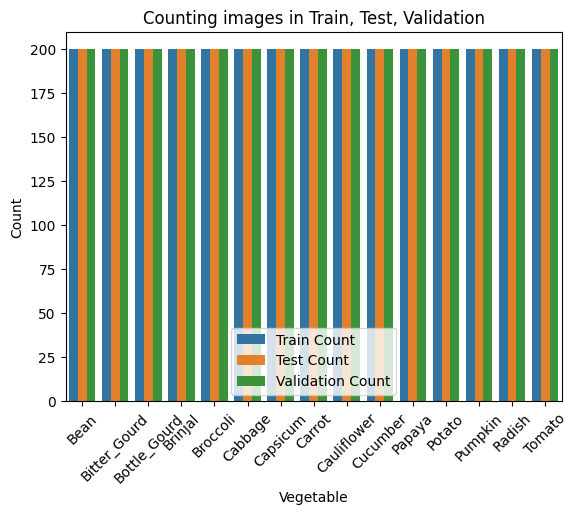

In [359]:
sns.barplot(data=df_melted,x='Vegetable',y='Count',hue='Dataset')
plt.title("Counting images in Train, Test, Validation")
plt.xticks(rotation=45)
plt.legend()
plt.show()

#Not balanced because Train is 1000 images
#but validation and testing each has 200 only

In [360]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [361]:
gen=ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2
)

In [362]:
train_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train"
test_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test"
validation_path= "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation"

In [363]:
train_data=gen.flow_from_directory(train_path,target_size=(224,224),class_mode='categorical',seed=42,batch_size=32)

Found 15000 images belonging to 15 classes.


In [364]:
test_data=gen.flow_from_directory(test_path,target_size=(224,224),class_mode='categorical',seed=42,batch_size=32)

Found 3000 images belonging to 15 classes.


In [365]:
validation_data=gen.flow_from_directory(validation_path,target_size=(224,224),class_mode='categorical',seed=42,batch_size=32)

Found 3000 images belonging to 15 classes.


In [366]:
from keras.layers import Flatten,Dense, Conv2D, MaxPooling2D


In [367]:
model=Sequential()

In [368]:
model.add(Input(shape=(224,224,3)))
model.add(Conv2D(32,kernel_size=(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(64,kernel_size=(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(128,kernel_size=(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())
model.add(Dense(512,activation=tf.keras.activations.relu))
model.add(Dropout(0.5))

model.add(Dense(15,activation=tf.keras.activations.softmax))



In [369]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [370]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_48 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │    51,380,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,481,679 (196.39 MB)

 Trainable params: 51,481,679 (196.39 MB)

 Non-trainable params: 0 (0.00 B)

- 3 Convolutional layers
- Max pooling layers are to reduce the parameters that will be learnt through minimizing the size by getting the highest pixel value in the kernel boundary to use instead of getting all values and this highest value will represent the other neighbours
- Dropout is to ensure that during every training step 50% of the layer will be turned off randomly
- Softmax is because we have more than 2 classes that we need to classify data on so it will give us the percentage of each class of them



In [371]:
early_stop=tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [372]:
history=model.fit(train_data,epochs=15,validation_data=validation_data,callbacks=early_stop)

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 52s 102ms/step - accuracy: 0.6363 - loss: 1.1111 - val_accuracy: 0.8447 - val_loss: 0.4799
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 94ms/step - accuracy: 0.8779 - loss: 0.3898 - val_accuracy: 0.9267 - val_loss: 0.2438
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 92ms/step - accuracy: 0.9268 - loss: 0.2326 - val_accuracy: 0.9533 - val_loss: 0.1596
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 93ms/step - accuracy: 0.9536 - loss: 0.1530 - val_accuracy: 0.9740 - val_loss: 0.1001
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 92ms/step - accuracy: 0.9614 - loss: 0.1267 - val_accuracy: 0.9660 - val_loss: 0.1319
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 92ms/step - accuracy: 0.9688 - loss: 0.0974 - val_accuracy: 0.9700 - val_loss: 0.1001
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 46s 97ms/step - accuracy: 0.9773 - loss: 0.0756 - val_accuracy: 0.9107 - val_loss: 0.3494
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 44s 94ms/step - accuracy: 0.9746 - loss: 0.0921 -

Early stop is useful as the epochs stop if they found that no learning is happening instead of continue computing without learning or change in accuracy

In [373]:
model.evaluate(validation_data)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.9770 - loss: 0.0923


[0.09225928038358688, 0.9769999980926514]

In [374]:
model.evaluate(test_data)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9760 - loss: 0.0939


[0.09394008666276932, 0.9760000109672546]

In [375]:
model.evaluate(train_data)

469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 75ms/step - accuracy: 0.9996 - loss: 0.0025


[0.00254119373857975, 0.9995999932289124]

The difference between training and validation is not large so it indicates that there is no overfitting

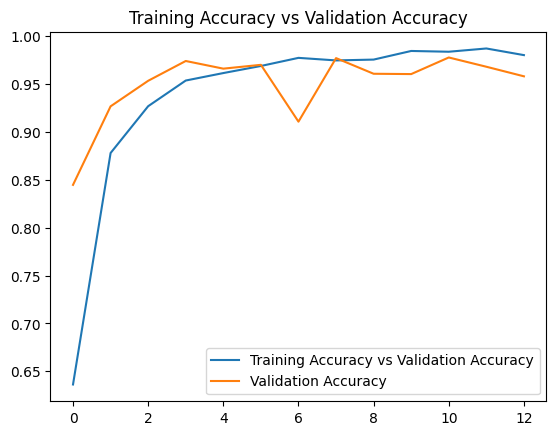

In [378]:
plt.plot(history.history['accuracy'],label="Training Accuracy vs Validation Accuracy")
plt.plot(history.history['val_accuracy'],label="Validation Accuracy")
plt.legend()
plt.title("Training Accuracy vs Validation Accuracy")
plt.show()

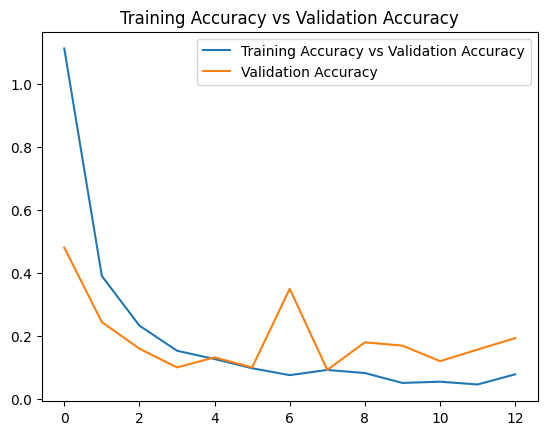

In [379]:
plt.plot(history.history['loss'],label="Training Accuracy vs Validation Accuracy")
plt.plot(history.history['val_loss'],label="Validation Accuracy")
plt.legend()
plt.title("Training Accuracy vs Validation Accuracy")
plt.show()